In [1]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib as mpl
import matplotlib.pyplot as plt
import patsy
from scipy.stats import chi2
import os

# 设置字体
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['axes.unicode_minus'] = False

# 请确认你的文件路径
path = r'C:\Users\13676\Desktop\senna_cohort.csv'

df = pd.read_csv(path, encoding='gb18030', encoding_errors='replace', low_memory=False)

time_cols = ['index_time', 'baseline_k_charttime', 'hypokalemia_time',
             'window_event_time', 'admittime', 'dischtime', 'deathtime',
             'baseline_egfr_charttime']
for c in time_cols:
    if c in df.columns:
        df[c] = pd.to_datetime(df[c], dayfirst=True, errors='coerce')

# 重建主数据集
df_main = df.dropna(subset=['senna_exposed', 'hypokalemia_event',
                             'baseline_k', 'age']).copy()
df_main['y'] = df_main['hypokalemia_event'].astype(int)
df_main['senna_exposed'] = df_main['senna_exposed'].astype(int)
df_main['gender_male'] = (df_main['gender'].str.upper().str[0] == 'M').astype(int)

print(f"✅ df_main 重建完成！行数: {len(df_main)}")

✅ df_main 重建完成！行数: 41529


In [3]:
# ==========================================
# 🔌 Step 2（修正版）：中重度低钾（K < 3.0）敏感性分析
# ==========================================

# 1. 使用正确的列名 'hypokalemia_k_value' 定义新结局
df_main['y_severe'] = (df_main['hypokalemia_k_value'] < 3.0).astype(int)

print(f"中重度低钾发生率: {df_main['y_severe'].mean()*100:.2f}%")
print(f"事件数: {df_main['y_severe'].sum()}")

# 2. 跑多因素回归
formula_severe = (
    'y_severe ~ senna_exposed + gender_male + '
    'C(age_group, Treatment("65-74")) + '
    'baseline_k + drug_count_no_laxatives + '
    'chf + ckd + dm + diuretic + acei_arb + digoxin + '
    'insulin + statin + anticoagulant + '
    'lactulose + peg + bisacodyl + '
    'ppi + beta2_agonist + corticosteroid'
)
model_severe = smf.logit(formula_severe, data=df_main).fit(disp=0)

# 3. 打印结果
or_sev = np.exp(model_severe.params['senna_exposed'])
lo_sev = np.exp(model_severe.conf_int().loc['senna_exposed', 0])
hi_sev = np.exp(model_severe.conf_int().loc['senna_exposed', 1])
p_sev  = model_severe.pvalues['senna_exposed']

print(f"\n✅ [结果] 中重度低钾 K<3.0: aOR = {or_sev:.3f} ({lo_sev:.3f}–{hi_sev:.3f}), P = {p_sev:.3g}")

中重度低钾发生率: 0.96%
事件数: 398

✅ [结果] 中重度低钾 K<3.0: aOR = 1.235 (0.982–1.553), P = 0.0717


In [5]:
# 注意：这里把公式里的 diarrhea_vomiting 删掉了
formula_no_diarrhea = (
    'y ~ senna_exposed + gender_male + '
    'C(age_group, Treatment("65-74")) + '
    'baseline_k + drug_count_no_laxatives + '
    'chf + ckd + dm + diuretic + acei_arb + digoxin + '
    'insulin + statin + anticoagulant + '
    'lactulose + peg + bisacodyl + '
    'ppi + beta2_agonist + corticosteroid'
)
model_no_diarr = smf.logit(formula_no_diarrhea, data=df_main).fit(disp=0)

or_nd = np.exp(model_no_diarr.params['senna_exposed'])
lo_nd = np.exp(model_no_diarr.conf_int().loc['senna_exposed', 0])
hi_nd = np.exp(model_no_diarr.conf_int().loc['senna_exposed', 1])
p_nd  = model_no_diarr.pvalues['senna_exposed']

print(f"✅ [结果] 不调整腹泻敏感性: aOR = {or_nd:.3f} ({lo_nd:.3f}–{hi_nd:.3f}), P = {p_nd:.3g}")

✅ [结果] 不调整腹泻敏感性: aOR = 1.190 (1.124–1.260), P = 2.53e-09


In [7]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# 1. 直接生成两个二分类变量，参照组为 > 4.5
df_main['k_lt_4'] = (df_main['baseline_k'] < 4.0).astype(int)
df_main['k_4_to_4_5'] = ((df_main['baseline_k'] >= 4.0) & (df_main['baseline_k'] <= 4.5)).astype(int)

# 2. 跑多因素模型
formula_score = (
    'y ~ k_lt_4 + k_4_to_4_5 + senna_exposed + gender_male + '
    'C(age_group, Treatment("65-74")) + '
    'drug_count_no_laxatives + '
    'chf + ckd + dm + diuretic + acei_arb + digoxin + '
    'insulin + statin + anticoagulant + '
    'lactulose + peg + bisacodyl + '
    'ppi + beta2_agonist + corticosteroid'
)
m_score = smf.logit(formula_score, data=df_main).fit(disp=0)

# 3. 提取并计算赋分
print("✅ [结果] SAHRS血钾赋分数学推导：")

# 提取 < 4.0 的系数
term_low = 'k_lt_4'
aor_low = np.exp(m_score.params[term_low])
beta_low = m_score.params[term_low]
points_low = round(beta_low / 0.15)
print(f"K < 4.0 vs >4.5: aOR = {aor_low:.3f}, β系数 = {beta_low:.3f}, 换算得分 = {points_low} 分")

# 提取 4.0-4.5 的系数
term_med = 'k_4_to_4_5'
aor_med = np.exp(m_score.params[term_med])
beta_med = m_score.params[term_med]
points_med = round(beta_med / 0.15)
print(f"K 4.0-4.5 vs >4.5: aOR = {aor_med:.3f}, β系数 = {beta_med:.3f}, 换算得分 = {points_med} 分")

✅ [结果] SAHRS血钾赋分数学推导：
K < 4.0 vs >4.5: aOR = 3.295, β系数 = 1.192, 换算得分 = 8 分
K 4.0-4.5 vs >4.5: aOR = 1.392, β系数 = 0.330, 换算得分 = 2 分


排除 K<3.8 后样本量: 35390


C:\Users\13676\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


✅ [结果] 排除 K<3.8 后, P for nonlinear = 3.9716e-36


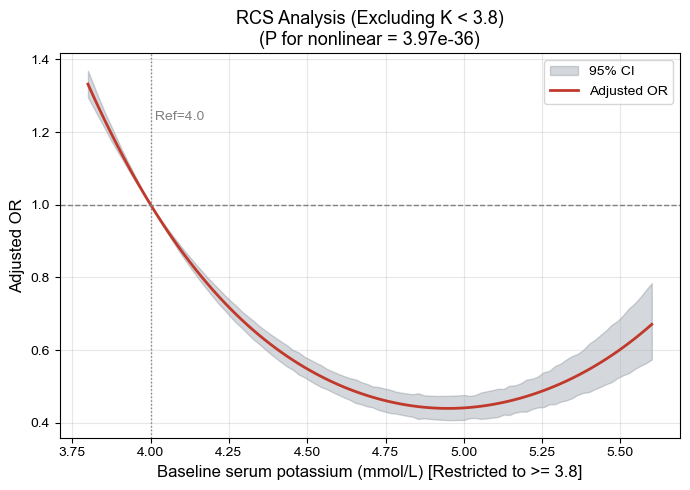

In [8]:
# 1. 排除 K<3.8 的样本
df_sub_rcs = df_main[df_main['baseline_k'] >= 3.8].copy()
print(f"排除 K<3.8 后样本量: {len(df_sub_rcs)}")

# 2. 拟合样条模型
COVARS = 'gender_male + C(age_group, Treatment("65-74")) + drug_count_no_laxatives + chf + ckd + dm + diuretic + acei_arb + digoxin + insulin + statin + anticoagulant + lactulose + peg + bisacodyl + ppi + beta2_agonist + corticosteroid'

model_spline = smf.logit(f'y ~ cr(baseline_k, df=3) + senna_exposed + {COVARS}', data=df_sub_rcs).fit(disp=0)
model_linear = smf.logit(f'y ~ baseline_k + senna_exposed + {COVARS}', data=df_sub_rcs).fit(disp=0)

# 3. 计算非线性 P 值
lr_stat = 2 * (model_spline.llf - model_linear.llf)
p_nonlinear = chi2.sf(lr_stat, 2)
print(f"✅ [结果] 排除 K<3.8 后, P for nonlinear = {p_nonlinear:.4e}")

# 4. 计算预测值并画图
ref_value = 4.0
x_range = np.linspace(df_sub_rcs['baseline_k'].quantile(0.01), df_sub_rcs['baseline_k'].quantile(0.99), 100)

pred_data = df_sub_rcs.iloc[0:len(x_range)].copy()
pred_data['baseline_k'] = x_range
pred_ref = pred_data.copy()
pred_ref['baseline_k'] = ref_value

X_spline = patsy.build_design_matrices([model_spline.model.data.design_info], pred_data, return_type='dataframe')[0]
X_ref    = patsy.build_design_matrices([model_spline.model.data.design_info], pred_ref, return_type='dataframe')[0]

log_odds_diff = np.dot(X_spline.values, model_spline.params) - np.dot(X_ref.values, model_spline.params)
cov_matrix = model_spline.cov_params()
diff_matrix = X_spline.values - X_ref.values
se = np.sqrt(np.diag(np.dot(np.dot(diff_matrix, cov_matrix), diff_matrix.T)))

OR = np.exp(log_odds_diff)
lower_ci = np.exp(log_odds_diff - 1.96 * se)
upper_ci = np.exp(log_odds_diff + 1.96 * se)

# 5. 绘图保存
fig, ax = plt.subplots(figsize=(7, 5))
ax.fill_between(x_range, lower_ci, upper_ci, color='#2C3E50', alpha=0.2, label='95% CI')
ax.plot(x_range, OR, color='#C0392B', linewidth=2, label='Adjusted OR')
ax.axhline(1, color='gray', linestyle='--', linewidth=1)
ax.axvline(ref_value, color='gray', linestyle=':', linewidth=1)
ax.text(ref_value, max(upper_ci)*0.9, f' Ref={ref_value}', color='gray', fontsize=10)
ax.set_xlabel('Baseline serum potassium (mmol/L) [Restricted to >= 3.8]', fontsize=12)
ax.set_ylabel('Adjusted OR', fontsize=12)
ax.set_title(f'RCS Analysis (Excluding K < 3.8)\n(P for nonlinear = {p_nonlinear:.2e})', fontsize=13)
ax.legend(loc='upper right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('Figure_RCS_Sensitivity_K38.png', dpi=300, bbox_inches='tight')
plt.show()

In [1]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import matplotlib as mpl
import matplotlib.pyplot as plt
import patsy
from scipy.stats import chi2
import os

# 设置字体
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['axes.unicode_minus'] = False

# 请确认你的文件路径
path = r'C:\Users\13676\Desktop\senna_cohort.csv'

df = pd.read_csv(path, encoding='gb18030', encoding_errors='replace', low_memory=False)

time_cols = ['index_time', 'baseline_k_charttime', 'hypokalemia_time',
             'window_event_time', 'admittime', 'dischtime', 'deathtime',
             'baseline_egfr_charttime']
for c in time_cols:
    if c in df.columns:
        df[c] = pd.to_datetime(df[c], dayfirst=True, errors='coerce')

# 重建主数据集
df_main = df.dropna(subset=['senna_exposed', 'hypokalemia_event',
                             'baseline_k', 'age']).copy()
df_main['y'] = df_main['hypokalemia_event'].astype(int)
df_main['senna_exposed'] = df_main['senna_exposed'].astype(int)
df_main['gender_male'] = (df_main['gender'].str.upper().str[0] == 'M').astype(int)

print(f"✅ df_main 重建完成！行数: {len(df_main)}")

✅ df_main 重建完成！行数: 41529


In [2]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf

# 1. 生成三分类变量，确保 4.0-4.5 能够被单独提取
# 假设你的 baseline_k 是连续变量，我们使用 pd.cut 生成分箱
# right=False 表示左闭右开：<4.0 包含 3.9；4.0-4.5 包含 4.0但不含4.5；>4.5 包含4.5及以上
df_main['k_group'] = pd.cut(df_main['baseline_k'], 
                            bins=[0, 4.0, 4.5, 100], 
                            labels=['<4.0', '4.0-4.5', '>4.5'],
                            right=False)

# 2. 在公式中显式指定参考组为 "4.0-4.5"
formula_score_ref = (
    'y ~ C(k_group, Treatment("4.0-4.5")) + senna_exposed + gender_male + '
    'C(age_group, Treatment("65-74")) + '
    'drug_count_no_laxatives + '
    'chf + ckd + dm + diuretic + acei_arb + digoxin + '
    'insulin + statin + anticoagulant + '
    'lactulose + peg + bisacodyl + '
    'ppi + beta2_agonist + corticosteroid'
)

# 3. 跑模型
m_score_ref = smf.logit(formula_score_ref, data=df_main).fit(disp=0)

# 4. 提取 `<4.0` vs `4.0-4.5` 的直接对比结果
term = 'C(k_group, Treatment("4.0-4.5"))[T.<4.0]'
aor_direct = np.exp(m_score_ref.params[term])
ci_low = np.exp(m_score_ref.conf_int().loc[term, 0])
ci_high = np.exp(m_score_ref.conf_int().loc[term, 1])
p_val = m_score_ref.pvalues[term]

print(f"直接对比 (<4.0 vs 4.0-4.5): aOR = {aor_direct:.3f}, 95% CI = ({ci_low:.3f} - {ci_high:.3f}), P = {p_val:.3e}")

直接对比 (<4.0 vs 4.0-4.5): aOR = 2.277, 95% CI = (2.151 - 2.412), P = 2.294e-174
